# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DOSSIER = Path("donnees")

brut = pd.read_csv(DOSSIER / "consommation_brut.csv")
print("Forme :", brut.shape)
print("\nType de chaque colonne :")
print(brut.dtypes)
print("\nValeurs manquantes par colonne :")
print(brut.isna().sum())
print("\nLignes en double :", brut.duplicated().sum())


Forme : (300, 4)

Type de chaque colonne :
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes par colonne :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
noms_bruts = sorted(brut["quartier"].unique())
print("Écritures différentes pour quartier :", len(noms_bruts))
print(noms_bruts)


Écritures différentes pour quartier : 43
[' Bas-Peu-de-Chose', ' Carénage', ' Delmas 33', ' Delmas 65', ' Delmas 75', ' Morne Calvaire', ' Petite-Anse', ' Place Saint-Pierre', ' Thomassin', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bas-Peu-de-Chose', 'Bas-Peu-de-Chose ', 'Bois-Verna', 'CARÉNAGE', 'CENTRE-VILLE', 'Carénage', 'Carénage ', 'Centre-ville', 'Centre-ville ', 'DELMAS 33', 'Delmas 33', 'Delmas 33 ', 'Delmas 65', 'Delmas 75', 'Delmas 75 ', 'Morne Calvaire', 'PLACE SAINT-PIERRE', 'Petite-Anse', 'Place Saint-Pierre', 'Place Saint-Pierre ', 'RUE 15', 'Rue 15', 'Rue 15 ', 'THOMASSIN', 'Thomassin', 'Thomassin ', 'bas-peu-de-chose', 'carénage', 'centre-ville', 'delmas 65', 'delmas 75', 'place saint-pierre']


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
converti = pd.to_numeric(brut["kwh"], errors="coerce")
non_convertibles = brut.loc[converti.isna() & brut["kwh"].notna(), "kwh"]
print("Valeurs non convertibles :", non_convertibles.nunique())
print(non_convertibles.drop_duplicates().tolist())


Valeurs non convertibles : 48
['184410 kWh', '206280 kWh', '215140 kWh', '251 900', '274520 kWh', '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh', '299610 kWh', '373 880', '333670 kWh', '597730 kWh', '456060 kWh', '495020 kWh', '409 300', '556 070', '260360 kWh', '347870 kWh', '408 780', '364 090', '243160 kWh', '154 720', '233 700', '253 300', '385840 kWh', '445270 kWh', '337 810', '366 390', '154 740', '170420 kWh', '201690 kWh', '81370 kWh', '139470 kWh', '77670 kWh', '139230 kWh', '121 240', '160110 kWh', '105 830', '163010 kWh', '198720 kWh', '281 240', '104 640', '166700 kWh', '73 110', '171 160', '187230 kWh']


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = (
    propre["kwh"].astype(str)
    .str.replace("kWh", "", case=False, regex=False)
    .str.replace(" ", "", regex=False)
    .str.strip()
)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
print("Manquants après conversion :", propre["kwh"].isna().sum())


Manquants après conversion : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv(DOSSIER / "quartiers.csv")
noms_officiels = {nom.lower(): nom for nom in quartiers["quartier"]}
propre["quartier"] = (
    propre["quartier"].str.strip().str.lower().map(noms_officiels)
)
print("Noms non reconnus :", propre["quartier"].isna().sum())
print("Quartiers distincts :", propre["quartier"].nunique())
print(sorted(propre["quartier"].unique()))


Noms non reconnus : 0
Quartiers distincts : 12
['Bas-Peu-de-Chose', 'Bois-Verna', 'Carénage', 'Centre-ville', 'Delmas 33', 'Delmas 65', 'Delmas 75', 'Morne Calvaire', 'Petite-Anse', 'Place Saint-Pierre', 'Rue 15', 'Thomassin']


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
print("Avant :", propre.shape)
propre = propre.drop_duplicates()
print("Après suppression des doublons :", propre.shape)
propre = propre.dropna(subset=["kwh"])
print("Après suppression des kwh manquants :", propre.shape)
propre = propre.reset_index(drop=True)


Avant : (300, 4)
Après suppression des doublons : (288, 4)
Après suppression des kwh manquants : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane_du_quartier = propre.groupby("quartier")["kwh"].transform("median")
trop_grands = propre["kwh"] > 3 * mediane_du_quartier
print("Relevés à corriger :", int(trop_grands.sum()))
print(propre.loc[trop_grands, ["mois", "quartier", "kwh"]].to_string(index=False))
propre.loc[trop_grands, "kwh"] = propre.loc[trop_grands, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)
print("\nMaximum de kwh :", propre["kwh"].max())


Relevés à corriger : 4
   mois       quartier       kwh
2025-02      Delmas 33 3602600.0
2025-02      Delmas 75 2012700.0
2024-02 Morne Calvaire 1439200.0
2024-01         Rue 15  997700.0

Maximum de kwh : 742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

*Note :* `consommation.csv` contient les 288 combinaisons quartier-mois, y compris les 9 lignes écartées faute de `kwh`. On le ramène donc aux 279 mêmes lignes avant de comparer.


In [8]:
reference = pd.read_csv(DOSSIER / "consommation.csv")
reference_alignee = (
    propre[["mois", "quartier"]]
    .merge(reference, on=["mois", "quartier"], how="left")
    [list(propre.columns)]
)
print("propre :", propre.shape, "| référence complète :", reference.shape)
print("Référence ramenée aux mêmes lignes :", reference_alignee.shape)
print("Identique au fichier de référence :", propre.equals(reference_alignee))


propre : (279, 4) | référence complète : (288, 5)
Référence ramenée aux mêmes lignes : (279, 4)
Identique au fichier de référence : True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
avec_quartiers = propre.merge(quartiers, on="quartier", how="left")
print("Avant :", len(propre), "| Après :", len(avec_quartiers))
avec_quartiers["kwh_par_abonne"] = (
    avec_quartiers["kwh"] / avec_quartiers["abonnes"]
).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)
print("\nBas-Peu-de-Chose en 2024-01 :")
print(
    avec_quartiers.loc[
        (avec_quartiers["quartier"] == "Bas-Peu-de-Chose")
        & (avec_quartiers["mois"] == "2024-01"),
        ["mois", "quartier", "commune", "kwh", "abonnes", "kwh_par_abonne", "annee"],
    ].to_string(index=False)
)


Avant : 279 | Après : 279

Bas-Peu-de-Chose en 2024-01 :
   mois         quartier        commune    kwh  abonnes  kwh_par_abonne  annee
2024-01 Bas-Peu-de-Chose Port-au-Prince 184410     2150            85.8   2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv(DOSSIER / "meteo.csv")
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="left")
print("Avant :", len(avec_quartiers), "| Après :", len(avec_meteo))
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())
print("Colonnes :", list(avec_meteo.columns))


Avant : 279 | Après : 279
Températures manquantes : 0
Colonnes : ['mois', 'quartier', 'kwh', 'heures_courant', 'commune', 'type', 'abonnes', 'kwh_par_abonne', 'annee', 'temperature_c', 'pluie_mm']


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
avec_meteo.to_csv(DOSSIER / "consommation_propre.csv", index=False)
propre_relu = pd.read_csv(DOSSIER / "consommation_propre.csv")
print("Forme du fichier enregistré :", propre_relu.shape)
print(propre_relu.head().to_string(index=False))


Forme du fichier enregistré : (279, 11)
   mois         quartier    kwh  heures_courant        commune        type  abonnes  kwh_par_abonne  annee  temperature_c  pluie_mm
2024-01 Bas-Peu-de-Chose 184410            10.6 Port-au-Prince Résidentiel     2150            85.8   2024           25.7        33
2024-02 Bas-Peu-de-Chose 195930            11.9 Port-au-Prince Résidentiel     2150            91.1   2024           25.5        40
2024-03 Bas-Peu-de-Chose 186560            10.2 Port-au-Prince Résidentiel     2150            86.8   2024           27.2        99
2024-04 Bas-Peu-de-Chose 236730            12.2 Port-au-Prince Résidentiel     2150           110.1   2024           27.4       119
2024-05 Bas-Peu-de-Chose 206280            10.2 Port-au-Prince Résidentiel     2150            95.9   2024           28.1       185


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

Moyenne par abonné selon le type :
type
Commercial     393.2
Résidentiel    117.4

Classement des 12 quartiers :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6


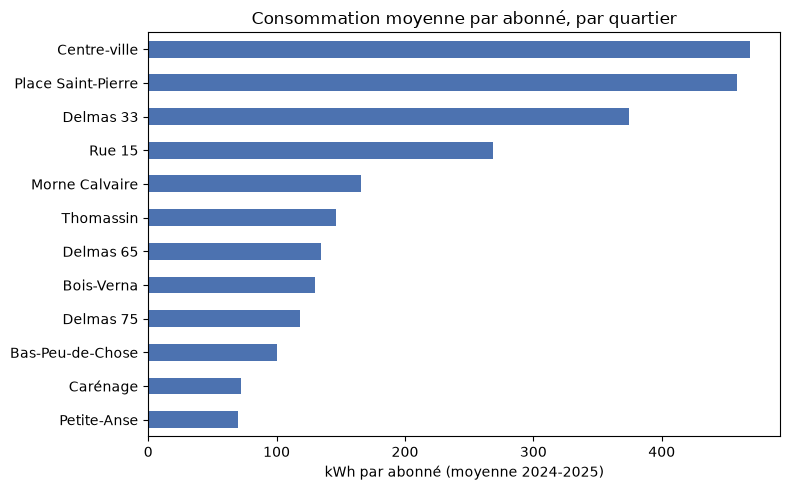

In [12]:
moyenne_par_type = avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1)
print("Moyenne par abonné selon le type :")
print(moyenne_par_type.to_string())

classement = (
    avec_meteo.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .sort_values(ascending=False)
    .round(1)
)
print("\nClassement des 12 quartiers :")
print(classement.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
classement.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("kWh par abonné (moyenne 2024-2025)")
ax.set_ylabel("")
ax.set_title("Consommation moyenne par abonné, par quartier")
plt.tight_layout()
plt.show()


**Ce qu'on en conclut :**

**Ce qu'on en conclut :** les quartiers commerciaux consomment en moyenne 393,2 kWh par abonné, contre 117,4 pour les résidentiels, soit plus de trois fois plus. Le classement est dominé par Centre-ville (468,7), Place Saint-Pierre (458,3) et Delmas 33 (374,4) ; Carénage (72,2) et Petite-Anse (69,6) ferment la marche.


**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Consommation totale par commune et par année (kWh) :
annee               2024      2025
commune                           
Cap-Haïtien      4587550   5617740
Delmas          11613360  11741410
Port-au-Prince  10085070  10313770
Pétion-Ville     8595330   9675080

Hausse en % :
commune
Cap-Haïtien       22.4
Delmas             1.1
Port-au-Prince     2.2
Pétion-Ville      12.6

Totaux en millions de kWh :
annee            2024   2025
commune                     
Cap-Haïtien      4.59   5.62
Delmas          11.61  11.74
Port-au-Prince  10.09  10.31
Pétion-Ville     8.60   9.68


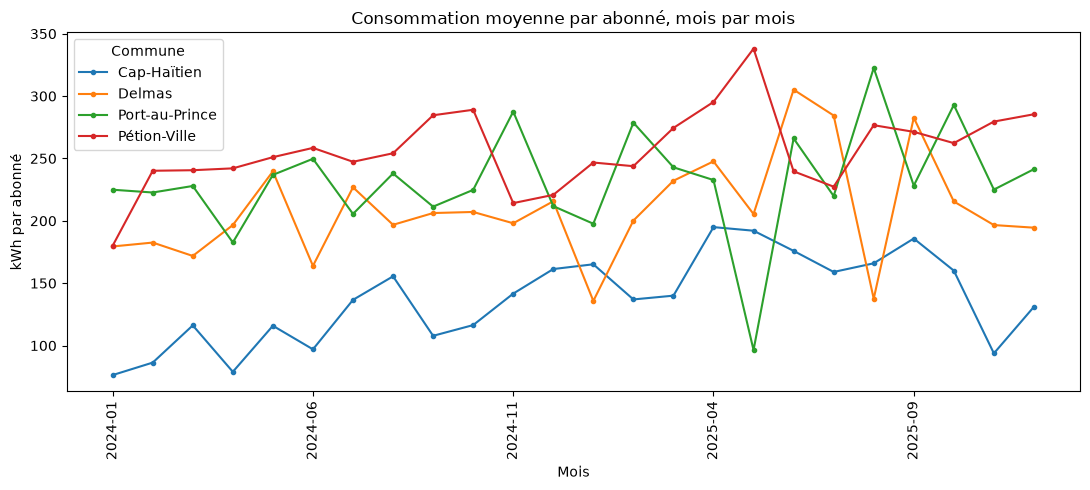

In [13]:
tableau_communes = avec_meteo.pivot_table(
    index="commune", columns="annee", values="kwh", aggfunc="sum"
)
print("Consommation totale par commune et par année (kWh) :")
print(tableau_communes.to_string())

totaux_millions = (tableau_communes / 1_000_000).round(2)
hausse = ((totaux_millions[2025] / totaux_millions[2024]) - 1) * 100
print("\nHausse en % :")
print(hausse.round(1).to_string())

print("\nTotaux en millions de kWh :")
print(totaux_millions.to_string())

courbes = (
    avec_meteo.groupby(["commune", "mois"])["kwh_par_abonne"].mean().unstack("commune")
)
fig, ax = plt.subplots(figsize=(11, 5))
courbes.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Consommation moyenne par abonné, mois par mois")
ax.set_xlabel("Mois")
ax.set_ylabel("kWh par abonné")
ax.tick_params(axis="x", rotation=90)
ax.legend(title="Commune")
plt.tight_layout()
plt.show()


**Ce qu'on en conclut :** Cap-Haïtien progresse le plus vite (+22,4 %, de 4,59 à 5,62 millions de kWh), suivi de Pétion-Ville (+12,6 %). Port-au-Prince, la plus grosse consommatrice, ne gagne que 2,2 %, et Delmas reste presque stable (+1,1 %).


## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

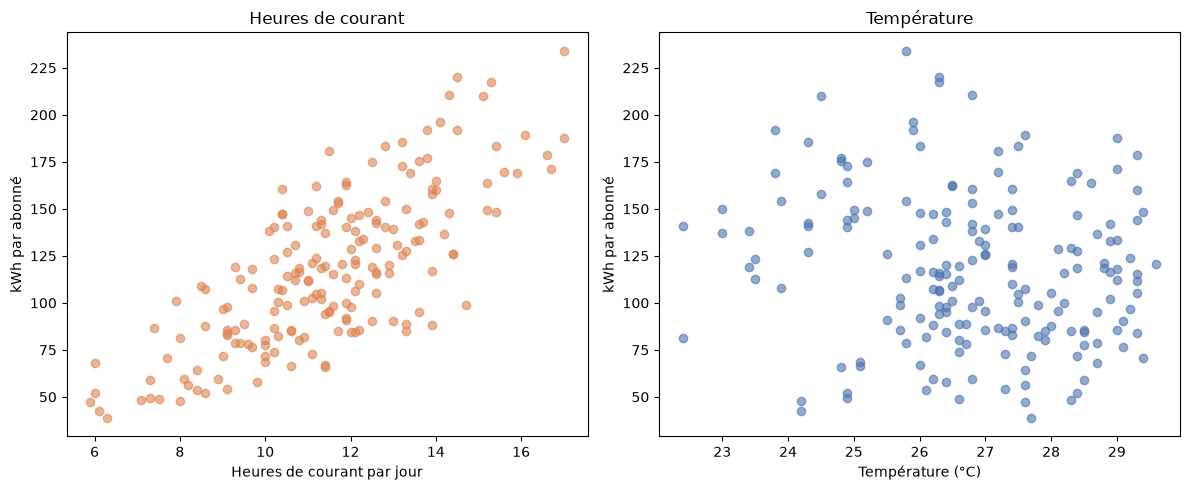

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [14]:
residentiel = avec_meteo[avec_meteo["type"] == "Résidentiel"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(
    residentiel["heures_courant"],
    residentiel["kwh_par_abonne"],
    alpha=0.6,
    color="#DD8452",
)
axes[0].set_xlabel("Heures de courant par jour")
axes[0].set_ylabel("kWh par abonné")
axes[0].set_title("Heures de courant")

axes[1].scatter(
    residentiel["temperature_c"],
    residentiel["kwh_par_abonne"],
    alpha=0.6,
    color="#4C72B0",
)
axes[1].set_xlabel("Température (°C)")
axes[1].set_ylabel("kWh par abonné")
axes[1].set_title("Température")
plt.tight_layout()
plt.show()

corr_heures = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"])
corr_temperature = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"])
print(f"Corrélation avec les heures de courant : {corr_heures:.2f}")
print(f"Corrélation avec la température : {corr_temperature:.2f}")


**Ce qu'on en conclut :** dans les quartiers résidentiels, la consommation par abonné suit nettement les heures de courant (r = 0,76) : plus le courant est disponible, plus on consomme. La température n'explique presque rien (r = -0,15), et va même légèrement à contre-sens. Une corrélation n'établit pas une causalité : elle ne dit pas si c'est le courant qui fait consommer ou l'inverse, et d'autres facteurs (revenus, équipements, saison, qualité des relevés) peuvent jouer.


## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Heures de courant par commune :
                mediane    q1    q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


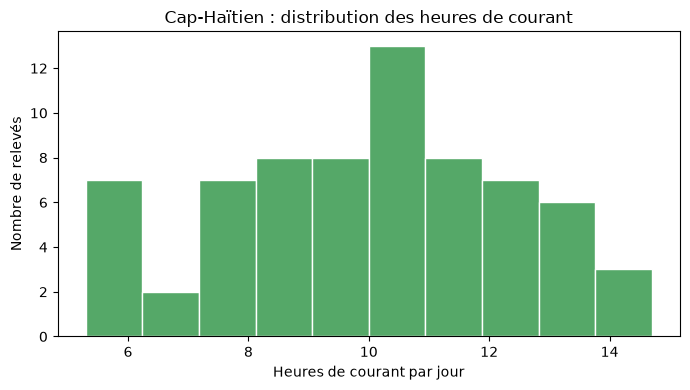

Relevés de 2025 sous 8 heures de courant : 3
   mois  quartier     commune  heures_courant
2025-01 Delmas 33      Delmas             7.4
2025-08  Carénage Cap-Haïtien             7.3
2025-11    Rue 15 Cap-Haïtien             5.9


In [15]:
stats_courant = (
    avec_meteo.groupby("commune")["heures_courant"]
    .agg(
        mediane="median",
        q1=lambda serie: serie.quantile(0.25),
        q3=lambda serie: serie.quantile(0.75),
    )
    .round(1)
)
print("Heures de courant par commune :")
print(stats_courant.to_string())

cap_haitien = avec_meteo[avec_meteo["commune"] == "Cap-Haïtien"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(cap_haitien["heures_courant"], bins=10, color="#55A868", edgecolor="white")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("Nombre de relevés")
ax.set_title("Cap-Haïtien : distribution des heures de courant")
plt.tight_layout()
plt.show()

faibles = avec_meteo[
    (avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8)
]
print("Relevés de 2025 sous 8 heures de courant :", len(faibles))
print(
    faibles[["mois", "quartier", "commune", "heures_courant"]].to_string(index=False)
)


**Ce qu'on en conclut :** Cap-Haïtien est la commune la plus mal servie, avec une médiane de 10,0 heures de courant par jour (Q1 à 8,3), contre 11,6 à 11,9 heures ailleurs. En 2025, seuls 3 relevés passent sous 8 heures : Delmas 33 en janvier (7,4), Carénage en août (7,3) et Rue 15 en novembre (5,9).


## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
plus_gros = avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
print("Les 3 plus grosses consommations :")
print(plus_gros.to_string(index=False))


Les 3 plus grosses consommations :
   mois     quartier       type    kwh
2025-07    Delmas 33 Commercial 742780
2024-11 Centre-ville Commercial 597730
2025-09    Delmas 33 Commercial 591420


**Ce qu'on en conclut :** les trois plus grosses consommations sont commerciales et concentrées à Delmas 33 et Centre-ville. Le maximum, Delmas 33 en juillet 2025 (742 780 kWh), reste le plus gros relevé du fichier même après correction du relevé saisi dix fois trop grand.


## 9. Conclusion

La consommation suit davantage les heures de courant que la chaleur : dans les quartiers résidentiels, la corrélation entre les kWh par abonné et les heures de courant atteint 0,76, contre -0,15 avec la température. Autrement dit, ce n'est pas la chaleur qui tire la demande, mais la disponibilité du réseau ; Cap-Haïtien, mal servi (médiane de 10,0 heures), progresse pourtant le plus (+22,4 %), ce qui invite à la prudence. Une corrélation n'établit pas une causalité : elle ne dit pas si c'est le courant qui fait consommer ou l'inverse, et d'autres facteurs (revenus, équipements, saisonnalité, qualité des relevés) peuvent expliquer une partie du lien.


## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.